# Reproducing the OT-tSNE paper figures

This notebook reproduces two paper figures from the files in `data/`:

1. embedding panels for seven real datasets;
2. top-$r$ finishes across biological-conservation and batch-mixing scores.

Start Jupyter in this `handoff/` directory, then run the notebook from top to bottom with a
fresh kernel. It depends only on NumPy, pandas and Matplotlib; no project source code is
imported. The configuration cell below controls the
datasets, regularisation, ranking variant and figure layout.

> **Font note:** The paper uses Arial. If an Arial-compatible font is unavailable, Matplotlib
> falls back to DejaVu Sans. This changes typography, but not the data, geometry or scores.


In [170]:
# Imports and configuration

%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.legend import Legend
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from matplotlib.collections import LineCollection

import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
import ot
from openTSNE import TSNE
from openTSNE.affinity import Affinities
from scipy.sparse import block_array
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pathlib import Path
import os

# The handoff data is not tracked by git. By default it is read from `handoff/data` at the repo
# root, found from this notebook's folder; set NE_ALIGNED_HANDOFF_DATA to read it from elsewhere
# (e.g. "/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/data_and_figures/data_and_figures/data_final_ICLR").
REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = Path(os.environ.get("NE_ALIGNED_HANDOFF_DATA", REPO_ROOT / "handoff" / "data"))

# Every figure this notebook writes goes here, never into DATA_DIR.
OUTPUT_DIR = Path(os.environ.get("NE_ALIGNED_FIGURE_DIR", REPO_ROOT / "handoff" / "figures"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = (
    "nCoV",
    "human_brain",
    "lupus",
    "yao_10x_ent_l2l3",
    "PBMC",
    "mouse_atlas",
    "hematopoietic",
)

EMBEDDING_DATASETS = DATASETS

TOP_R_DATASETS = DATASETS

REL_REG = 1.0

NORMALIZATION = "minmax"

TOP_R = 3

TOP_R_FORM = "tall"

SAVE_DPI = 600

STYLE_FILE = DATA_DIR / "style.mplstyle"
LONG_FRAME_CSV = DATA_DIR / "scored_long_frame.csv"
METHOD_REGISTRY_CSV = DATA_DIR / "method_registry.csv"
EMBEDDING_DIR = DATA_DIR / "embeddings"

plt.style.use(str(STYLE_FILE))

FULL_WIDTH = 5.500

MULTIMAP_METHOD_KEY = "multimap"

SEED = 0


---

## 1. Embedding panels

**Input:** one `data/embeddings/<dataset>.npz` file per dataset. Each file contains seed-0 2D
coordinates for nine methods, plus batch and cell-type labels.

**Output:** one two-row figure per dataset. Columns are methods; rows show the same coordinates
coloured by batch and by cell type. The vertical rule separates the unintegrated reference from
the integration methods.

Only the two-item batch legend is included. Cell-type names are best supplied in the paper
caption because some datasets contain up to 22 types.


In [115]:
# Embedding figure settings

EMBEDDING_OUTPUT_DIR = None        # e.g. Path("figures")

QUALITATIVE_COLUMNS = (
    ("joint", "Unintegrated\n(joint t-SNE)"),
    ("ot", "OT-tSNE"),
    (MULTIMAP_METHOD_KEY, "MultiMAP"),
    ("rc-tsne", "RC t-SNE"),
    ("seurat-50", "Seurat\n50D"),
    ("liger-50", "LIGER\n50D"),
    ("scanorama-50", "Scanorama\n50D"),
    ("scvi-50", "scVI\n50D"),
    ("eot-50", "EOT\n50D"),
)

QUALITATIVE_ROWS = (("batch", "Batch"), ("cell type", "Cell type"))

QUALITATIVE_TITLE_PT = 8.0

QUALITATIVE_BATCH_COLOURS = ("#377eb8", "#e66101")
QUALITATIVE_BATCH_LABELS = ("Batch 0", "Batch 1")

QUALITATIVE_MARGINS = {
    "left": 0.05,
    "right": 0.20,
    "top": 0.30,
    "bottom": 0.05,
    "wgap": 0.04,
    "hgap": 0.04,
}

QUALITATIVE_RULE_AT = 0.5

QUALITATIVE_LEGEND_GAP = 0.10

QUALITATIVE_HANDLETEXTPAD = 0.25
QUALITATIVE_COLUMNSPACING = 1.2

_POINT_REF_SIZE = 3.5
_POINT_REF_N = 4060

PANEL_TRIM = 0.002


In [116]:
# Embedding plot helpers

def square_grid(ncols, nrows, *, width=FULL_WIDTH, left, right, top, bottom, wgap, hgap,
                legend=0.0):
    """Figure size that makes every panel square, plus the resulting panel side in inches.

    The returned side is a target, not a guarantee: the height is computed from the assumed
    margins, while `constrained_layout` then lays out from the actual content.
    """
    usable = width - left - right - (ncols - 1) * wgap
    panel = usable / ncols
    height = top + bottom + nrows * panel + (nrows - 1) * hgap + legend
    return (width, height), panel

def cell_type_palette(cell_type_names, cmap_name="tab20"):
    """One RGBA colour per cell type, from a resampled qualitative colormap."""
    cmap = plt.get_cmap(cmap_name, len(cell_type_names))
    return np.array([cmap(i) for i in range(len(cell_type_names))])

def point_size(n):
    """Marker area for an embedding of `n` points, in points squared."""
    return float(_POINT_REF_SIZE * np.sqrt(_POINT_REF_N / max(n, 1)))

def fill_panel(ax, emb):
    """Frame a panel on the bulk of its points, at 1:1 aspect."""
    lo = np.quantile(emb, PANEL_TRIM, axis=0)
    hi = np.quantile(emb, 1.0 - PANEL_TRIM, axis=0)
    centre = (lo + hi) / 2
    half = float(np.max(hi - lo)) / 2 * 1.06
    ax.set_xlim(centre[0] - half, centre[0] + half)
    ax.set_ylim(centre[1] - half, centre[1] + half)
    ax.set_aspect("equal", adjustable="box")

def batch_legend(palette_colors=QUALITATIVE_BATCH_COLOURS):
    """(handles, labels, ncol) for the batch key -- the only key this figure carries."""
    handles = [
        Line2D([], [], marker="o", linestyle="none", markersize=4,
               markerfacecolor=color, markeredgecolor="none")
        for color in palette_colors
    ]
    return handles, list(QUALITATIVE_BATCH_LABELS), len(QUALITATIVE_BATCH_LABELS)

def measure_legend_block(block, width):
    """(width, height) in inches of one key, measured by drawing it.

    Reserving a fixed row height is deliberately generous -- it exists to stop a legend squeezing
    the panels. Here the band holds one short row and that generosity is simply white space.
    """
    handles, labels, ncol = block
    scratch = plt.figure(figsize=(width, 1.0))
    ax = scratch.add_subplot(111)
    ax.axis("off")
    drawn = Legend(ax, handles, labels, loc="lower left", ncol=ncol, frameon=False,
                   borderaxespad=0.0, handletextpad=QUALITATIVE_HANDLETEXTPAD,
                   columnspacing=QUALITATIVE_COLUMNSPACING, labelspacing=0.3, alignment="left")
    ax.add_artist(drawn)
    extent = drawn.get_window_extent(scratch.canvas.get_renderer())
    plt.close(scratch)
    return extent.width / scratch.dpi, extent.height / scratch.dpi

def qualitative_legend(legend_ax, block):
    """The batch key, centred under the panels."""
    handles, labels, ncol = block
    drawn = Legend(
        legend_ax, handles, labels, loc="center", ncol=ncol, frameon=False,
        borderaxespad=0.0, handletextpad=QUALITATIVE_HANDLETEXTPAD,
        columnspacing=QUALITATIVE_COLUMNSPACING, labelspacing=0.3,
    )
    legend_ax.add_artist(drawn)

def qualitative_rule(fig, axes):
    """The vertical rule setting the baseline column apart from the methods.

    Measured from the drawn axes rather than from their gridspec cells: the panels are square
    with `adjustable="box"`, so each sits centred in a cell wider or taller than itself and the
    gap between two cells is not the gap between two panels.
    """
    inv = fig.transFigure.inverted()
    boxes = [[ax.get_window_extent().transformed(inv) for ax in row] for row in axes]
    x = boxes[0][0].x1 + QUALITATIVE_RULE_AT * (boxes[0][1].x0 - boxes[0][0].x1)
    fig.add_artist(
        Line2D([x, x], [boxes[-1][0].y0, boxes[0][0].y1], transform=fig.transFigure,
               color="#000000", linewidth=0.6)
    )


In [117]:
# Load and validate embedding data

def load_embedding_arrays(dataset):
    """One dataset's seed-0 coordinates, batch ids, cell-type labels and cell-type names."""
    with np.load(EMBEDDING_DIR / f"{dataset}.npz", allow_pickle=False) as loaded:
        return {key: loaded[key] for key in loaded.files}

EMBEDDINGS = {dataset: load_embedding_arrays(dataset) for dataset in EMBEDDING_DATASETS}

for dataset, arrays in EMBEDDINGS.items():
    multimap_keys = sorted(k for k in arrays if k.startswith("embedding__multimap"))
    expected = [f"embedding__{MULTIMAP_METHOD_KEY}"]
    if multimap_keys != expected:
        raise ValueError(
            f"{dataset}: expected native MultiMAP embedding {expected}, got {multimap_keys}"
        )
    n = len(arrays["batch_ids"])
    print(f"{dataset:<20} {n:>6} cells, {len(arrays['label_names']):>2} cell types, "
          f"{sum(k.startswith('embedding__') for k in arrays)} methods")


nCoV                   4117 cells, 15 cell types, 9 methods
human_brain            9215 cells,  9 cell types, 9 methods
lupus                 13999 cells, 13 cell types, 9 methods
yao_10x_ent_l2l3      26588 cells, 22 cell types, 9 methods
PBMC                  15476 cells,  9 cell types, 9 methods
mouse_atlas            6954 cells, 11 cell types, 9 methods
hematopoietic          4649 cells,  7 cell types, 9 methods


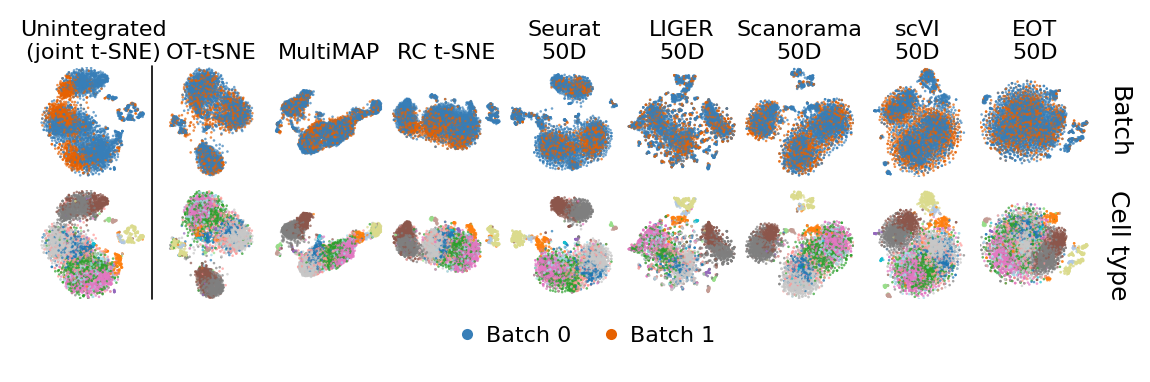

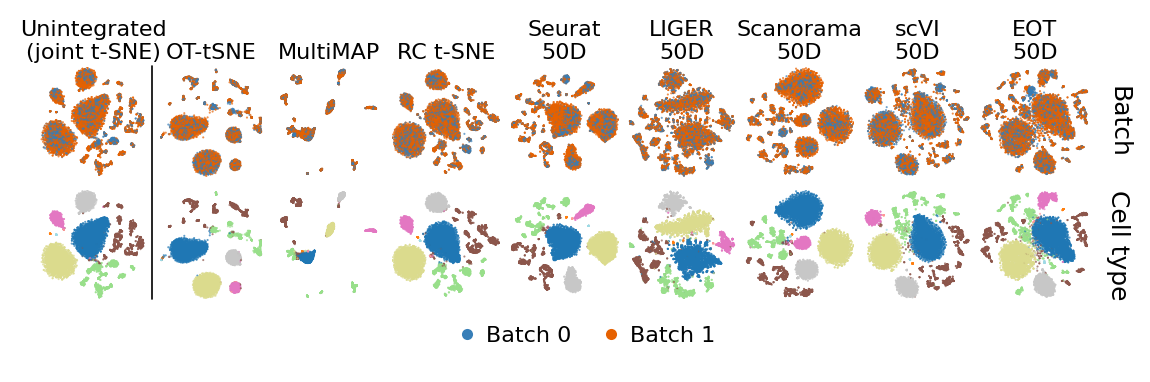

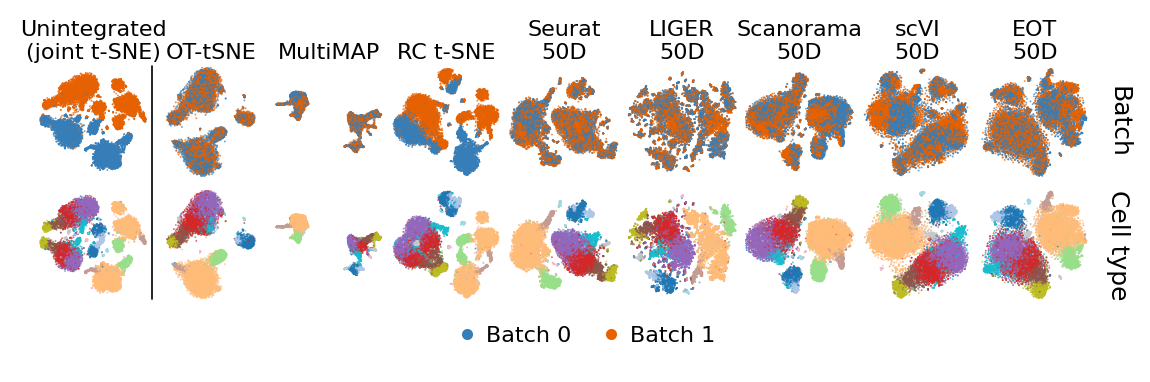

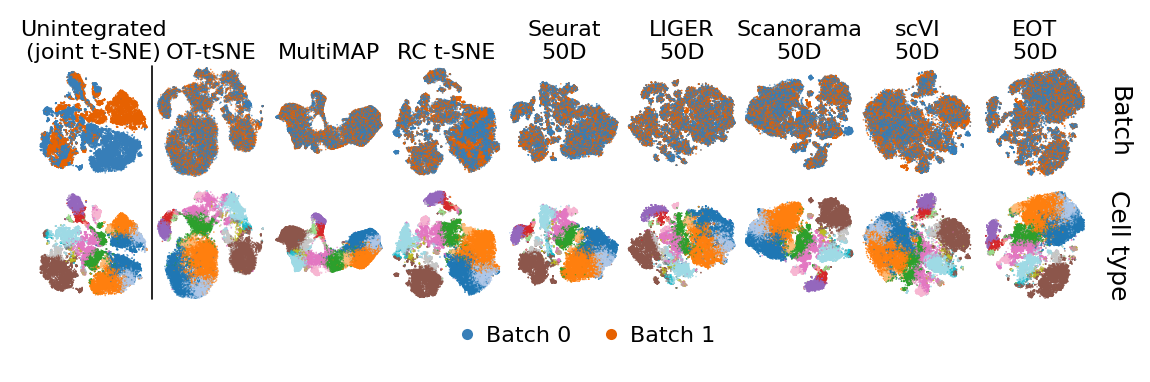

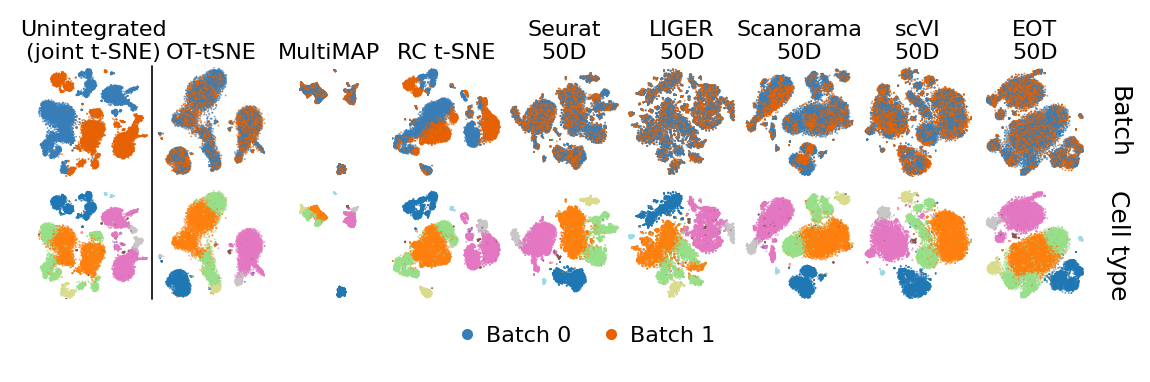

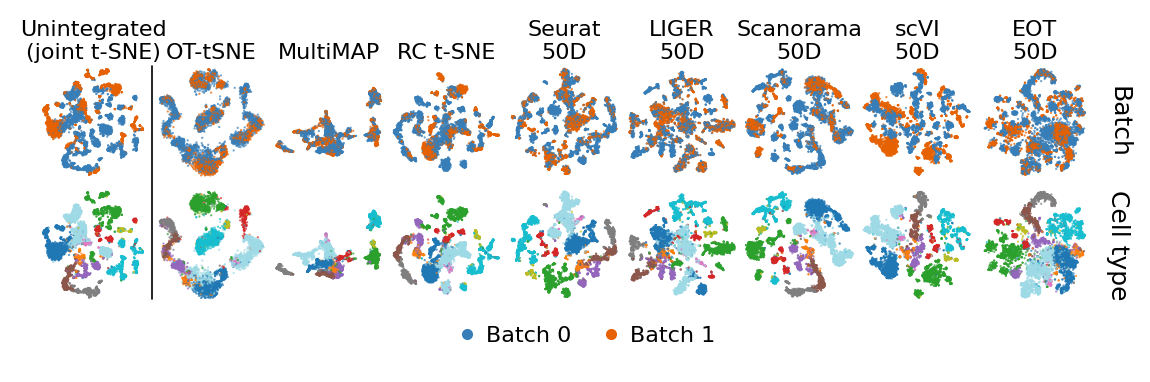

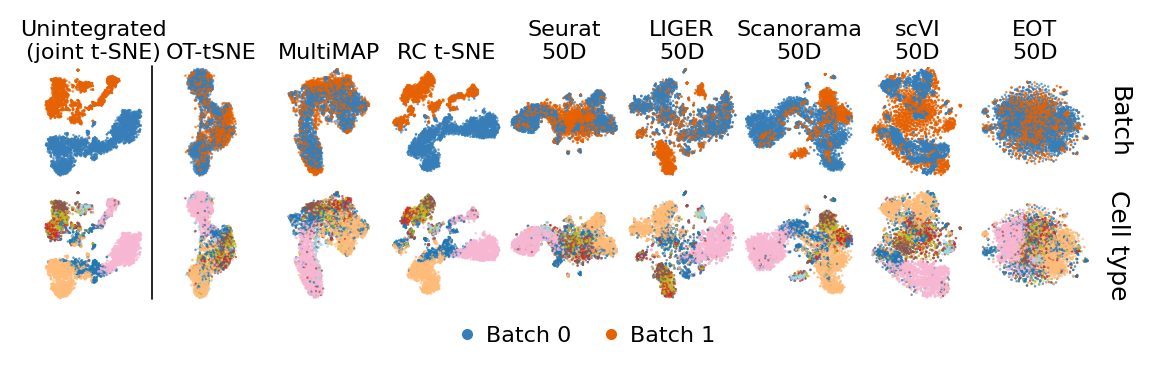

In [118]:
# Draw embedding panels

def embedding_panels(dataset, *, columns=QUALITATIVE_COLUMNS, title_pt=QUALITATIVE_TITLE_PT):
    """One dataset's embeddings: methods across, batch over cell type down.

    Points are drawn in random order, with partial transparency and no marker edge, at a size
    scaled by the cell count. There are no ticks, labels or frame: these coordinates have no
    units and no meaningful origin.
    """
    arrays = EMBEDDINGS[dataset]
    palette = cell_type_palette(tuple(str(x) for x in arrays["label_names"]))
    batch_colors = np.asarray(QUALITATIVE_BATCH_COLOURS)[
        np.asarray(arrays["batch_ids"], dtype=int)
    ]
    label_colors = palette[
        np.concatenate([arrays["labels0"], arrays["labels1"]]).astype(int)
    ]

    block = batch_legend()
    reserved = measure_legend_block(block, FULL_WIDTH)[1] + QUALITATIVE_LEGEND_GAP
    figsize, _panel = square_grid(
        len(columns), len(QUALITATIVE_ROWS), legend=reserved, **QUALITATIVE_MARGINS
    )
    fig = plt.figure(figsize=figsize)
    outer = fig.add_gridspec(2, 1, height_ratios=[figsize[1] - reserved, reserved])
    inner = outer[0].subgridspec(len(QUALITATIVE_ROWS), len(columns))
    axes = [[fig.add_subplot(inner[r, c]) for c in range(len(columns))]
            for r in range(len(QUALITATIVE_ROWS))]
    legend_ax = fig.add_subplot(outer[1])
    legend_ax.axis("off")
    rng = np.random.default_rng(SEED)

    for c, (key, heading) in enumerate(columns):
        emb = np.asarray(arrays[f"embedding__{key}"])
        order = rng.permutation(len(emb))
        for r, (color_kind, row_label) in enumerate(QUALITATIVE_ROWS):
            colors = batch_colors if color_kind == "batch" else label_colors
            ax = axes[r][c]
            ax.scatter(
                emb[order, 0], emb[order, 1], c=colors[order], s=point_size(len(emb)),
                alpha=0.7, linewidths=0, edgecolors="none", zorder=-1,
            )
            ax.set(xticks=[], yticks=[])
            fill_panel(ax, emb)
            for spine in ax.spines.values():
                spine.set_visible(False)
            if c == len(columns) - 1:
                ax.yaxis.set_label_position("right")
                ax.set_ylabel(row_label, rotation=270, va="bottom", labelpad=6)
            if r == 0:
                ax.set_title(heading, fontsize=title_pt)

    qualitative_legend(legend_ax, block)
    fig.canvas.draw()
    qualitative_rule(fig, axes)
    return fig

for dataset in EMBEDDING_DATASETS:
    fig = embedding_panels(dataset)
    if EMBEDDING_OUTPUT_DIR is not None:
        path = Path(EMBEDDING_OUTPUT_DIR) / f"f_embeddings_{dataset}.png"
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=SAVE_DPI, bbox_inches=None)
        print(f"wrote {path}")
    plt.show()


---

## 2. Top-$r$ finishes

**Input:** `data/scored_long_frame.csv` and `data/method_registry.csv`.

For each dataset, the calculation:

1. averages each metric over seeds;
2. orients all metrics so higher is better;
3. min-max normalises within each dataset and metric (`NORMALIZATION = "raw"` skips this step);
4. averages metrics into biological-conservation and batch-mixing scores;
5. ranks methods separately on both scores.

Each dataset contributes three finishes per score family, so seven datasets contribute 42
finishes in total. Bars are split by dataset and score family. Zero-finish methods are omitted
from the plot but remain in the competitor pool.


In [171]:
# Load score data

TOP_R_OUTPUT_PATH = None       # e.g. Path("figures/f_top_r_finishes.png")

long_frame = pd.read_csv(LONG_FRAME_CSV)
method_registry = pd.read_csv(METHOD_REGISTRY_CSV).set_index("key")

multimap_rows = long_frame[long_frame["method_key"].str.startswith("multimap", na=False)]
multimap_keys = sorted(multimap_rows["method_key"].unique())
if multimap_keys != [MULTIMAP_METHOD_KEY]:
    raise ValueError(
        f"expected only native MultiMAP key {MULTIMAP_METHOD_KEY!r}, got {multimap_keys}"
    )
if not multimap_rows["n_neighbors"].eq(30.0).all():
    raise ValueError("native two-batch MultiMAP rows must record n_neighbors=30")

print(f"{len(long_frame)} scored rows over {long_frame['dataset'].nunique()} datasets, "
      f"{long_frame['method_key'].nunique()} methods, {long_frame['seed'].nunique()} seeds")
long_frame.head()


483 scored rows over 7 datasets, 23 methods, 3 seeds


,dataset,dataset_label,backend,tree,method_key,method,method_label,family,subfamily,tool,...,rel_reg,effective_k,n_neighbors,init,result_source,supplementary_manifest,purity,silhouette,ilisi,kbet
0,nCoV,nCoV,na,direct_2d_cpu,bc-tsne,bc-tsne,BC t-SNE,dedicated,dedicated,bctsne,...,NaN,NaN,NaN,random,frozen_benchmark,NaN,0.664938,0.557836,0.361252,0.566645
1,nCoV,nCoV,na,direct_2d_cpu,bc-tsne,bc-tsne,BC t-SNE,dedicated,dedicated,bctsne,...,NaN,NaN,NaN,random,frozen_benchmark,NaN,0.663451,0.566228,0.359537,0.528154
2,nCoV,nCoV,na,direct_2d_cpu,bc-tsne,bc-tsne,BC t-SNE,dedicated,dedicated,bctsne,...,NaN,NaN,NaN,random,frozen_benchmark,NaN,0.664050,0.564569,0.357274,0.549261
3,nCoV,nCoV,na,direct_2d_cpu,eot-t0,eot-t0,EOT 2D,integration,ot-baseline,eot,...,1.0,NaN,NaN,random,frozen_benchmark,NaN,0.370114,0.488029,0.479223,0.622432
4,nCoV,nCoV,na,direct_2d_cpu,eot-t0,eot-t0,EOT 2D,integration,ot-baseline,eot,...,1.0,NaN,NaN,random,frozen_benchmark,NaN,0.370114,0.488029,0.479223,0.622432


In [172]:
# Scoring vocabulary

METRIC_SOURCE_COLUMNS = {
    "neighborhood_purity_score": "purity",
    "silhouette_score": "silhouette",
    "ilisi_score": "ilisi",
    "kbet_score": "kbet",
}

NO_BACKEND = "na"

RANK_METRICS = (
    "neighborhood_purity_score",
    "silhouette_score",
    "ilisi_score",
    "kbet_score",
)

METRIC_FAMILY = {
    "neighborhood_purity_score": "bio",
    "silhouette_score": "bio",
    "ilisi_score": "batch",
    "kbet_score": "batch",
}

METRIC_DIRECTION = {
    "neighborhood_purity_score": +1,
    "silhouette_score": +1,
    "ilisi_score": +1,
    "kbet_score": +1,
}

FAMILY_TO_SCORE = {"bio": "bio", "batch": "mixing"}

SCORES = ("bio", "mixing", "overall")

NORM_SUFFIX = "__norm"

DEPRECATED_METHODS = ("cca-2d-uncentered", "cca-50-uncentered")

OT_EFFECTIVE_K = 15.0

# The benchmark frame contains one native MultiMAP arm, so no arm has to be dropped here.
EXCLUDED_METHODS = ()


BIO_WEIGHT = 0.5


In [173]:
# Score-before-rank helpers

def metric_sides(metrics):
    """{"bio": (...), "mixing": (...)} for `metrics`, from `METRIC_FAMILY`.

    Raises when either side is empty: a bio score with no bio metric in it would still produce a
    number, and that number would mean nothing.
    """
    sides = {"bio": [], "mixing": []}
    for metric in metrics:
        family = METRIC_FAMILY.get(metric)
        if family is None:
            raise ValueError(f"{metric!r} cannot be attributed to the bio or the mixing side.")
        sides[FAMILY_TO_SCORE[family]].append(metric)
    empty = [side for side, members in sides.items() if not members]
    if empty:
        raise ValueError(f"no {' or '.join(empty)} metric among {list(metrics)}.")
    return {side: tuple(members) for side, members in sides.items()}

def oriented(values, metric):
    """`values` turned so that larger is better, staying inside [0, 1].

    A lower-is-better metric is reflected as `1 - x` rather than negated. Negation would order it
    correctly and give the identical min-max result, but it would put the raw variant on [-1, 0]
    and make its average with a higher-is-better metric meaningless.
    """
    if METRIC_DIRECTION.get(metric, +1) > 0:
        return values
    outside = values.dropna()
    if not outside.empty and (outside.min() < 0.0 or outside.max() > 1.0):
        raise ValueError(f"{metric!r} is lower-is-better but lies outside [0, 1].")
    return 1.0 - values

def minmax(values):
    """(x - min) / (max - min) over one ranking cell, with the degenerate case named.

    A cell where every method scores identically has no range to divide by. Returning 0 is the
    limit of the formula and is harmless -- a constant column shifts every method's composite by
    the same amount and so cannot change a rank computed within that dataset.
    """
    low, high = float(values.min()), float(values.max())
    span = high - low
    if not np.isfinite(span):
        raise ValueError(f"non-finite values in a normalisation cell: [{low}, {high}]")
    if span == 0.0:
        return pd.Series(0.0, index=values.index)
    return (values - low) / span

def expand_non_rel_reg_methods(rows, rel_reg_values):
    """Broadcast configuration-free methods across the regularisation grid.

    A method with no regularisation knob holds one score valid in every table. Giving it an
    explicit row per value is why its rank can still change between tables: its own value is
    fixed, but its competitors' are not.
    """
    rel_reg_free = rows[rows["rel_reg"].isna()].copy()
    swept = rows[rows["rel_reg"].notna()].copy()
    if rel_reg_free.empty:
        return swept
    expanded = [rel_reg_free.assign(rel_reg=float(e)) for e in rel_reg_values]
    return pd.concat([swept, *expanded], ignore_index=True)

def resolve_method_pool(rows, datasets):
    """Methods present on every dataset in `datasets`.

    The intersection is what makes the aggregate valid: every method is then ranked against the
    same competitors on every dataset, so the mean ranks are on a common footing.
    """
    present = {ds: set(rows.loc[rows["dataset"] == ds, "method"].unique()) for ds in datasets}
    missing = [ds for ds, ms in present.items() if not ms]
    if missing:
        raise ValueError(f"no scored rows for dataset(s) {missing}")
    common = set.intersection(*present.values())
    common -= set(DEPRECATED_METHODS)
    return tuple(sorted(common))

def check_complete_cells(grouped, pool, metrics):
    """Every (dataset, rel_reg) cell holds every pooled method, with no missing metric.

    A missing method changes the min-max denominator for every other method in that cell; a
    missing metric value makes one method's composite an average over fewer terms than its
    competitors'. Either is a silently wrong number rather than a visible failure.
    """
    counts = grouped.groupby(["dataset", "rel_reg"], dropna=False).size()
    short = counts[counts != len(pool)]
    if not short.empty:
        raise ValueError(
            f"the competitor pool holds {len(pool)} methods but these cells hold a different "
            f"number, so min-max would be computed against a different field in each:\n{short}"
        )
    missing = grouped[grouped[list(metrics)].isna().any(axis=1)]
    if not missing.empty:
        raise ValueError(
            f"{len(missing)} row(s) have a missing metric, so their composite would average over "
            f"fewer terms than their competitors':\n{missing[['dataset', 'method', 'rel_reg']].head(10)}"
        )

def score_within(rows, *, metrics=RANK_METRICS, datasets=None, rel_reg_values,
                 effective_k=OT_EFFECTIVE_K, normalization="minmax", bio_weight=BIO_WEIGHT):
    """Steps 1-5: seed means, normalisation, the three scores, and the dataset-level ranks.

    Returns one row per (dataset, method, rel_reg) carrying each metric's seed mean and its
    normalised value, then `bio_score` / `mixing_score` / `overall_score`, then `bio_rank` /
    `mixing_rank` / `overall_rank`, plus `n_competitors`. Best = rank 1; exact ties take the
    average of the ranks they span.
    """
    if normalization not in ("minmax", "raw"):
        raise ValueError(f"normalization must be 'minmax' or 'raw', got {normalization!r}")

    frame = rows.copy()
    if datasets is not None:
        frame = frame[frame["dataset"].isin(list(datasets))]
    if effective_k is not None and "effective_k" in frame.columns:
        frame = frame[frame["effective_k"].isna() | (frame["effective_k"] == effective_k)]
    if frame.empty:
        raise ValueError("no rows left after filtering; check datasets/effective_k")

    metrics = [m for m in metrics if m in frame.columns]
    if not metrics:
        raise ValueError("none of the requested metrics are present in the input frame")
    sides = metric_sides(metrics)

    keys = ["dataset", "method", "rel_reg"]
    grouped = frame.groupby(keys, dropna=False)[list(metrics)].mean().reset_index()

    grouped = expand_non_rel_reg_methods(grouped, rel_reg_values)
    wanted = [float(e) for e in rel_reg_values]
    grouped = grouped[grouped["rel_reg"].isin(wanted)]
    if grouped.empty:
        raise ValueError(f"no rows at rel_reg {wanted}")

    present = sorted(grouped["dataset"].unique()) if datasets is None else list(datasets)
    pool = resolve_method_pool(grouped, present)
    if not pool:
        raise ValueError(f"no method is present on all of {present}")
    grouped = grouped[grouped["method"].isin(pool)]

    check_complete_cells(grouped, pool, metrics)

    pieces = []
    for _cell, block in grouped.groupby(["dataset", "rel_reg"], sort=False):
        scored = block.copy()
        for metric in metrics:
            values = oriented(scored[metric], metric)
            scored[f"{metric}{NORM_SUFFIX}"] = (
                minmax(values) if normalization == "minmax" else values
            )
        scored["bio_score"] = scored[[f"{m}{NORM_SUFFIX}" for m in sides["bio"]]].mean(axis=1)
        scored["mixing_score"] = scored[
            [f"{m}{NORM_SUFFIX}" for m in sides["mixing"]]
        ].mean(axis=1)
        scored["overall_score"] = (
            float(bio_weight) * scored["bio_score"]
            + (1.0 - float(bio_weight)) * scored["mixing_score"]
        )
        for side in SCORES:
            scored[f"{side}_rank"] = scored[f"{side}_score"].rank(
                ascending=False, method="average"
            )
        pieces.append(scored)

    out = pd.concat(pieces, ignore_index=True)
    out["n_competitors"] = len(pool)
    out["normalization"] = normalization
    out["bio_weight"] = float(bio_weight)
    return out.sort_values(["rel_reg", "dataset", "overall_rank"]).reset_index(drop=True)


In [174]:
# Compute top-r finishes

def scored_shape(frame, *, backend="tsne"):
    """The long frame in the column names the scoring code expects.

    Rows whose backend is `na` come from methods that computed their own 2D layout, so they
    belong to every backend's table. The raw method string is dropped first: the frame carries
    both it and `method_key`, and renaming `method_key` onto "method" while the original is still
    present yields two columns of that name.
    """
    inverse = {short: long for long, short in METRIC_SOURCE_COLUMNS.items()}
    accepted = {backend, NO_BACKEND}
    data = frame[frame["backend"].isin(accepted)].copy()
    return data.drop(columns=["method"]).rename(columns={**inverse, "method_key": "method"})

def score_top_k_frequency(frame, *, datasets, rel_reg, normalization="minmax", top_k=TOP_R,
                          backend="tsne", exclude=()):
    """Per (dataset, method), whether it placed top-`top_k` on the bio side and the mixing side.

    `exclude` drops methods from the competition, before the pool is resolved -- not a display
    filter. Everything downstream is a placing, and a placing is defined against a pool: drop a
    method after ranking and the figure shows numbers that still describe a wider field, with a
    rank silently missing wherever the dropped method placed. Under min-max it reaches further
    still, since the removed method may have been the one setting a metric's 0 or 1.
    """
    rows = scored_shape(frame, backend=backend)
    if len(exclude):
        rows = rows[~rows["method"].isin(list(exclude))]
    scored = score_within(
        rows,
        datasets=list(datasets),
        rel_reg_values=(float(rel_reg),),
        normalization=normalization,
    )
    placed = scored.assign(
        n_top_k_bio=(scored["bio_rank"] <= float(top_k)).astype(int),
        n_top_k_batch=(scored["mixing_rank"] <= float(top_k)).astype(int),
    ).rename(columns={"method": "method_key"})
    counts = placed[["dataset", "method_key", "n_top_k_bio", "n_top_k_batch"]].copy()
    counts["n_top_k"] = counts["n_top_k_bio"] + counts["n_top_k_batch"]
    counts["n_cells"] = len(SCORES) - 1
    counts["normalization"] = normalization
    return counts.reset_index(drop=True)

COUNTS = score_top_k_frequency(
    long_frame,
    datasets=TOP_R_DATASETS,
    rel_reg=REL_REG,
    normalization=NORMALIZATION,
    exclude=EXCLUDED_METHODS,
)
print(f"{COUNTS['method_key'].nunique()} methods competing on "
      f"{COUNTS['dataset'].nunique()} datasets, "
      f"{int(COUNTS['n_top_k'].sum())} placings out of "
      f"{COUNTS['dataset'].nunique() * (len(SCORES) - 1) * TOP_R}")
COUNTS.groupby("method_key")["n_top_k"].sum().sort_values(ascending=False).head(8)


23 methods competing on 7 datasets, 42 placings out of 42


method_key
ot               6
multimap@nn30    6
seurat-2d        4
liger-50         3
rc-tsne          3
ref              3
eot-50           2
seurat-50        2
Name: n_top_k, dtype: int64

In [175]:
# Bar-plot settings

CLUSTER_DATASET_PALETTE = {
    "nCoV": "#3f2b7a",
    "human_brain": "#2a55b0",
    "lupus": "#1683c0",
    "yao_10x_ent_l2l3": "#0f9e8e",
    "PBMC": "#4aab3a",
    "mouse_atlas": "#c9a227",
    "hematopoietic": "#e2671c",
}

FINAL_DATASET_LABELS = {
    "nCoV": "nCoV",
    "human_brain": "Human brain",
    "lupus": "Lupus",
    "yao_10x_ent_l2l3": "Mouse cortex",
    "PBMC": "PBMC",
    "mouse_atlas": "Mouse atlas",
    "hematopoietic": "Hematopoietic",
}

# Label overrides for the bar plot; empty, since the registry labels are used as they are.
LEGEND_LABELS = {}

BAR_LABEL_RULES = ((" diagonal)", ")"),)

FAMILY_ORDER = ("ot", "dedicated", "integration", "reference")

BAR_PARTS = (("n_top_k_bio", "////"), ("n_top_k_batch", None))

# How the pieces are stacked inside one bar. Both orders are lexicographic on the same pair of
# keys and differ only in which one is outer. "dataset" runs (dataset, metric), so a dataset's bio
# and mixing finishes sit together and each colour appears once per bar. "metric" runs
# (metric, dataset), so every bio finish precedes every mixing one and each colour appears twice.
# The order within each key is untouched: datasets follow `CLUSTER_DATASET_PALETTE`, metrics
# follow `BAR_PARTS`.
BAR_SEGMENT_ORDER = "metric"  # "dataset", "metric"

BAR_LEGEND_LOC = "lower right"
BAR_LEGEND_PAD = 0.2

BAR_LABEL_CLEARANCE = 0.12

BAR_FORMS = {
    "split": {"columns": 2, "width": None, "height": 2.05, "legend_ncol": 1, "font_pt": None},
    "tall": {"columns": 1, "width": 3.50, "height": 3.00, "legend_ncol": 1, "font_pt": 9.0},
}

BAR_PANEL_FRACTION = 0.70


In [176]:
# Bar-plot helpers

def method_order(keys):
    """Registry keys sorted by family, then sub-family, then shade, then marker.

    Marker last so that a tool's two forms stay adjacent and always in the same order.
    """
    marker_rank = {"o": 0, "s": 1, "D": 0, "^": 0, "v": 0, "+": 0, "x": 0}
    return sorted(
        keys,
        key=lambda k: (
            FAMILY_ORDER.index(method_registry.at[k, "family"]),
            method_registry.at[k, "subfamily"],
            int(method_registry.at[k, "shade"]),
            marker_rank[method_registry.at[k, "marker"]],
        ),
    )

def bar_method_order(counts):
    """Methods by total placings, descending, ties broken by the registry's own order.

    The registry tiebreak matters: without it two methods on the same total swap places between
    runs, and a figure that reorders itself for no reason is a figure nobody trusts.
    """
    totals = counts.groupby("method_key")["n_top_k"].sum()
    canonical = {k: i for i, k in enumerate(method_order(totals.index))}
    return sorted(totals.index, key=lambda k: (-float(totals[k]), canonical[k]))

def bar_label(key):
    """The registry's full method name, respelled for print. See `BAR_LABEL_RULES`."""
    label = LEGEND_LABELS.get(key) or str(method_registry.at[key, "label"])
    for old, new in BAR_LABEL_RULES:
        label = label.replace(old, new)
    return label

def style_axes(ax, *, outward=2.0):
    """Offset the spines so axes that do not meet at zero show a visible corner gap."""
    for side in ("left", "bottom"):
        ax.spines[side].set_position(("outward", outward))
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def trim_axis(axes):
    """Shrink the x axis to the counts printed at the bar ends, plus one label's clearance.

    One limit for every column. Trimmed per axes, the two columns of the split form come back
    fitted to their own longest bar, and a bar of a given length would then mean a different
    number on each side.
    """
    axes = list(axes)
    axes[0].figure.canvas.draw()
    ends = [
        text.get_window_extent().transformed(ax.transData.inverted()).x1
        for ax in axes
        for text in ax.texts
        if text.get_text() and text not in {ax.title, ax.xaxis.label, ax.yaxis.label}
    ]
    if not ends:
        return
    for ax in axes:
        ax.set_xlim(0, max(ends) + BAR_LABEL_CLEARANCE)

def bar_segments(per_dataset, segment_order=BAR_SEGMENT_ORDER):
    """The (dataset, metric column, hatch) pieces of one bar, in stacking order.

    Both orders hold the same pieces, so a bar is the same length either way and only where each
    piece sits along it changes. See `BAR_SEGMENT_ORDER` for the two nestings.
    """
    if segment_order == "dataset":
        return [(dataset, column, hatch)
                for dataset in per_dataset for column, hatch in BAR_PARTS]
    if segment_order == "metric":
        return [(dataset, column, hatch)
                for column, hatch in BAR_PARTS for dataset in per_dataset]
    raise ValueError(f"segment order must be 'dataset' or 'metric', got {segment_order!r}")

def draw_bar_column(ax, order, wides, totals, *, hues, per_dataset, span,
                    segment_order=BAR_SEGMENT_ORDER):
    """Draw one column of the top-three bars, and return its y positions."""
    y = np.arange(len(order))
    left = np.zeros(len(order))
    for dataset, column, hatch in bar_segments(per_dataset, segment_order):
        values = wides[column].reindex(index=order)[dataset].to_numpy(dtype=float)
        ax.barh(
            y, values, left=left, height=0.72, color=hues[dataset],
            edgecolor="#ffffff", linewidth=0.4, hatch=hatch, zorder=2,
        )
        left += values

    for yi, value in zip(y, totals.reindex(order).to_numpy(dtype=float)):
        ax.text(value + 0.012 * span, yi, f"{value:g}", va="center", ha="left",
                fontsize=float(plt.rcParams["xtick.labelsize"]))

    ax.set(yticks=y, yticklabels=[bar_label(k) for k in order])
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.set_xlim(0, span * 1.10)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(axis="y", length=0)
    style_axes(ax)
    return y


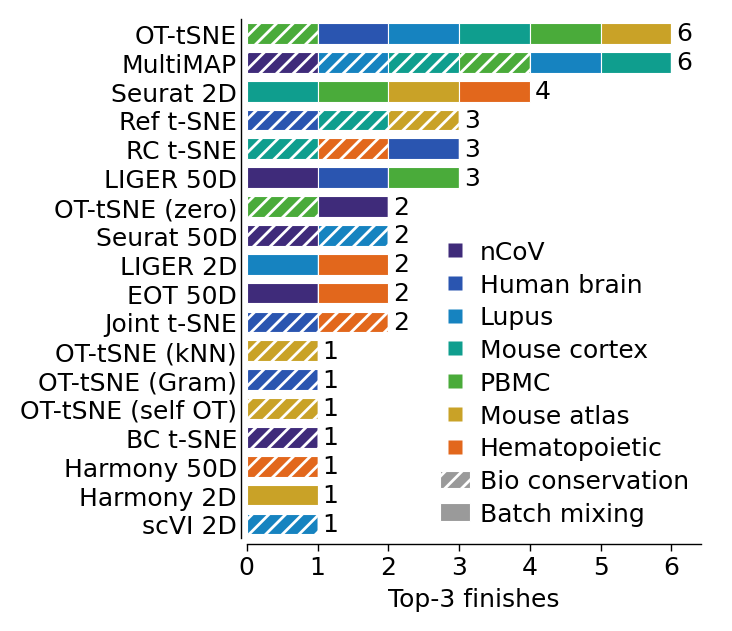

In [177]:
# Draw the top-r figure

def top_r_finishes(counts, *, family_labels=("Bio conservation", "Batch mixing"),
                       columns, width, height, legend_ncol, font_pt, drop_zeros=True, segment_order=BAR_SEGMENT_ORDER):
    """Horizontal bars: one per method, its length the number of top-r finishes."""
    order = bar_method_order(counts)
    totals = counts.groupby("method_key")["n_top_k"].sum().reindex(order)
    if drop_zeros:
        order = [key for key in order if totals[key] > 0]
        totals = totals.reindex(order)
        counts = counts[counts["method_key"].isin(order)]

    sizes = (
        {}
        if font_pt is None
        else {key: float(font_pt) for key in
              ("axes.labelsize", "xtick.labelsize", "ytick.labelsize", "legend.fontsize")}
    )
    with plt.rc_context(sizes):
        hues = dict(CLUSTER_DATASET_PALETTE)
        per_dataset = [d for d in hues if d in set(counts["dataset"])]
        span = max(1.0, float(totals.max()))
        wides = {
            column: counts.pivot_table(
                index="method_key", columns="dataset", values=column, aggfunc="sum",
                fill_value=0,
            ).reindex(columns=per_dataset, fill_value=0)
            for column, _hatch in BAR_PARTS
        }

        fig = plt.figure(figsize=(FULL_WIDTH, height) if width is None else (width, height))
        share = BAR_PANEL_FRACTION if columns == 1 and width is None else 1.0
        grid = fig.add_gridspec(
            1, columns + 1,
            width_ratios=[share / columns] * columns + [max(1.0 - share, 1e-6)],
        )
        axes = [fig.add_subplot(grid[0, i]) for i in range(columns)]
        fig.add_subplot(grid[0, columns]).axis("off")
        for ax, chunk in zip(axes, np.array_split(np.asarray(order, dtype=object), columns)):
            draw_bar_column(ax, list(chunk), wides, totals, hues=hues,
                            per_dataset=per_dataset, span=span,
                            segment_order=segment_order)

        handles = [
            Line2D([], [], marker="s", linestyle="none", markersize=5,
                   markerfacecolor=hues[d], markeredgecolor="none")
            for d in per_dataset
        ] + [
            Patch(facecolor="#9a9a9a", edgecolor="#ffffff", linewidth=0.4, hatch="////"),
            Patch(facecolor="#9a9a9a", edgecolor="#ffffff", linewidth=0.4),
        ]
        axes[-1].legend(
            handles=handles,
            labels=[FINAL_DATASET_LABELS.get(d, d) for d in per_dataset] + list(family_labels),
            loc=BAR_LEGEND_LOC, ncol=legend_ncol, frameon=False,
            borderaxespad=BAR_LEGEND_PAD, handletextpad=0.4, columnspacing=1.0,
            labelspacing=0.35,
        )

        trim_axis(axes)
        label = fig.supxlabel(f"Top-{TOP_R} finishes", fontsize=float(plt.rcParams["axes.labelsize"]))
        fig.canvas.draw()
        boxes = [ax.get_position() for ax in axes]
        label.set_x(0.5 * (boxes[0].x0 + boxes[-1].x1))
    return fig

fig = top_r_finishes(COUNTS, **BAR_FORMS[TOP_R_FORM])
if TOP_R_OUTPUT_PATH is not None:
    path = Path(TOP_R_OUTPUT_PATH)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches=None)
    print(f"wrote {path}")
plt.show()


In [153]:
def get_disc(n, r=1, seed=0):
    np.random.seed(seed)
    theta = 2 * np.pi * np.random.rand(n)
    # sqrt of a uniform makes the density uniform over the area rather than over the radius
    rad = r * np.sqrt(np.random.rand(n))

    return np.stack([rad * np.cos(theta), rad * np.sin(theta)], axis=1)

def get_wiggly_line(n, length=2.0, amp=0.25, n_waves=1.5, jitter=0.05, seed=0):
    np.random.seed(seed)
    x = np.sort(np.random.rand(n)) * length
    y = amp * np.sin(2 * np.pi * n_waves * x / length) + jitter * np.random.randn(n)

    return np.stack([x, y], axis=1)

In [14]:
def get_edges(nbrs, keys, queries, k, drop_self=True):
    # column 0 is the query point itself only when keys and queries are the same set.
    # for cross-batch queries it is the genuine nearest neighbour, so keep it.
    _, indices = nbrs.kneighbors(queries)
    indices = indices[:, 1:k+1] if drop_self else indices[:, :k]
    edges = np.stack([np.repeat(np.arange(len(queries)), k), indices.flatten()], axis=-1)
    segments = np.stack([queries[edges[:, 0]], keys[edges[:, 1]]], axis=1)
    return edges, segments


def first_per_point(arr, k, m):
    """Keep the m nearest of each query point's k edges.

    Relies on get_edges emitting each query's k edges contiguously and distance-sorted,
    so no re-sorting or distance recomputation is needed. Works both for the (n*k, 2)
    edge arrays and the (n*k, 2, d) segment arrays.
    """
    return arr.reshape(len(arr) // k, k, *arr.shape[1:])[:, :m].reshape(-1, *arr.shape[1:])


In [15]:

def sparsify_plan(P, mode=None, k=15):
    if mode is None:
        P_sparse = P

    elif mode == "topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = 1
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = 1

    elif mode == "weighted_topk":
        P_sparse = np.zeros_like(P)
        for i in range(P.shape[0]):
            idx = np.argpartition(P[i], -k)[-k:]
            P_sparse[i, idx] = P[i, idx]
        for j in range(P.shape[1]):
            idx = np.argpartition(P[:, j], -k)[-k:]
            P_sparse[idx, j] = P[idx, j]
    else:

        raise NotImplementedError

    return P_sparse

def subsample(x, num, seed=0):
    np.random.seed(seed)
    r = np.random.randn(len(x))
    part = np.argsort(r)
    if isinstance(num, int):
        n = num
    else:
        n = np.floor(len(x)*num).astype(int)
    return x[part[:n]]

In [198]:
def run_case(batch1, batch2, k=12, m_plot=3, seed=0, ot_eps_div=200, ot_maxiter=3000):
    """Build the four affinity graphs for one pair of batches and embed each of them.

    Returns the segments needed for the input row and the four embeddings for the output row.
    """

    # get knn and mutual knn edges
    nbrs1 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch1)
    edges11, segments11 = get_edges(nbrs1, batch1, batch1, k)
    edges12, segments12 = get_edges(nbrs1, batch1, batch2, k, drop_self=False)

    nbrs2 = NearestNeighbors(n_neighbors=k+1, algorithm='auto').fit(batch2)
    edges21, segments21 = get_edges(nbrs2, batch2, batch1, k, drop_self=False)
    edges22, segments22 = get_edges(nbrs2, batch2, batch2, k)


    # within batch kNN
    sep_graph = sp.coo_matrix((np.ones(len(edges11)+ len(edges22)),
                               (np.concatenate([edges11[:, 0], edges22[:, 0]+len(batch1)]),
                                np.concatenate([edges11[:, 1], edges22[:, 1]+len(batch1)]))),
                                shape=(len(batch1)+ len(batch2), len(batch1)+ len(batch2)))
    sep_graph = sep_graph.maximum(sep_graph.T)


    # cross batch
    graph12 = sp.coo_matrix(( np.ones(len(edges12)), (edges12[:,0], edges12[:, 1])), shape=(len(batch2), len(batch1)))
    graph21 = sp.coo_matrix(( np.ones(len(edges21)), (edges21[:,1], edges21[:, 0])), shape=(len(batch2), len(batch1)))

    # mutual kNN
    m_graph = graph12.minimum(graph21).tocoo()

    sep_m_graph = sep_graph +  block_array([[None, m_graph],
                                            [m_graph.T,  None],],
                                           format="csr")
    sep_m_graph /= sep_m_graph.sum()


    m_edges = np.stack([m_graph.row, m_graph.col], axis=-1)
    m_segments = np.stack([batch2[m_edges[:, 0]], batch1[m_edges[:, 1]]], axis=1)

    # shared kNN
    s_graph = graph12.maximum(graph21).tocoo()
    sep_s_graph = sep_graph +  block_array([[None, s_graph],
                                            [s_graph.T,  None],],
                                           format="csr")
    sep_s_graph /= sep_s_graph.sum()

    s_edges = np.stack([s_graph.row, s_graph.col], axis=-1)
    s_segments = np.stack([batch2[s_edges[:, 0]], batch1[s_edges[:, 1]]], axis=1)


    # shared kNN restricted to each point's m_plot nearest cross-batch neighbours, for drawing
    # only. the full-k graphs above still drive the embeddings. going through the sparse union
    # deduplicates edges that both directions find, which would otherwise be drawn twice.
    e12_top = first_per_point(edges12, k, m_plot)
    e21_top = first_per_point(edges21, k, m_plot)

    g12_top = sp.coo_matrix((np.ones(len(e12_top)), (e12_top[:, 0], e12_top[:, 1])),
                            shape=(len(batch2), len(batch1)))
    g21_top = sp.coo_matrix((np.ones(len(e21_top)), (e21_top[:, 1], e21_top[:, 0])),
                            shape=(len(batch2), len(batch1)))

    s_graph_plot = g12_top.maximum(g21_top).tocoo()
    s_edges_plot = np.stack([s_graph_plot.row, s_graph_plot.col], axis=-1)
    s_segments_plot = np.stack([batch2[s_edges_plot[:, 0]], batch1[s_edges_plot[:, 1]]], axis=1)


    # get ot plan
    dist = ot.dist(batch1, batch2)

    eps = np.median(dist) / ot_eps_div

    P = ot.sinkhorn(np.ones(len(batch1))/len(batch1),
                    np.ones(len(batch2))/len(batch2),
                            dist,
                            reg=eps,
                            numItermax=ot_maxiter,
                            stopThr=1e-12)

    P_sp = sp.coo_matrix(sparsify_plan(P, mode="topk", k=k))

    ot_segments = np.stack([batch1[P_sp.row], batch2[P_sp.col]], axis=1)


    # highest-mass couplings per point, for drawing only. topk keeps the top k per row and per
    # column, so every point ends up with at least k_sub partners and none is left isolated.
    k_sub = m_plot
    P_sp_sub = sp.coo_matrix(sparsify_plan(P, mode="topk", k=k_sub))

    ot_segments_sub = np.stack([batch1[P_sp_sub.row], batch2[P_sp_sub.col]], axis=1)

    sep_ot_graph = sep_graph +  block_array([[None, P_sp],
                                            [P_sp.T,  None],],
                                           format="csr")
    sep_ot_graph /= sep_ot_graph.sum()

    # only normalize sep_graph here so not have it dwarfed by the off-diag blocks
    sep_graph /= sep_graph.sum()


    # get embeddings, all from the same initialization so only the affinities differ
    init = np.concatenate([batch1, batch2])[:, :2] / 10000

    embds = {}
    for name, graph in [("joint_tsne", sep_graph), ("m_tsne", sep_m_graph),
                        ("s_tsne", sep_s_graph), ("ot_tsne", sep_ot_graph)]:
        aff = Affinities()
        aff.P = graph
        embedder = TSNE(
            n_components=2,
            random_state=seed,
            verbose=False,
        )
        embds[name] = embedder.fit(affinities=aff, initialization=init)

    return {"segments11": segments11, "segments22": segments22,
            "segments12": segments12, "segments21": segments21,
            "m_segments": m_segments,
            "s_segments": s_segments, "s_segments_plot": s_segments_plot,
            "ot_segments": ot_segments, "ot_segments_sub": ot_segments_sub,
            "sep_graph": sep_graph, "sep_m_graph": sep_m_graph,
            "sep_s_graph": sep_s_graph, "sep_ot_graph": sep_ot_graph,
            **embds}

# wrapped, because in the composite these headings sit over panels narrower than themselves
CASE_COL_TITLES = ("Naive kNN",
                   "Mutual\ncross kNN",
                   "Shared\ncross kNN",
                   "Optimal\ntransport")

CASE_ROW_TITLES = ("Input", "Output")


def case_col_titles(first):
    """The column headings, with any `{first}` filled in by the naive-kNN panel's own letter.

    That letter is `a` when this case is a figure of its own and `c` inside the composite, so a
    heading that refers back to that panel cannot be a constant.

    Headings shorter than their neighbours are padded with trailing blank lines. matplotlib
    aligns a title on its last line, so a one-line `naive kNN` would otherwise sit a line below
    the wrapped headings beside it -- and below its own panel letter.
    """
    titles = [title.format(first=first) for title in CASE_COL_TITLES]
    tallest = max(title.count("\n") for title in titles)
    return [title + "\n" * (tallest - title.count("\n")) for title in titles]


def draw_case_panels(ax, batch1, batch2, res, n0, *, letters="abcd", col_titles=None,
                     row_titles=CASE_ROW_TITLES, colours=QUALITATIVE_BATCH_COLOURS,
                     s=5, alpha=0.2, m_frac=0.5, sub_seed=0, plot_seed=0,
                     letter_rows=(0,), letter_pt=7, title_pad=None, legend_ax=None):
    """Input row (data + edges) over output row (embeddings), into a 2x4 array of existing axes.

    Taking the axes rather than making them is what lets the same drawing serve both `plot_case`
    and the composite figure. `letters` runs across the grid row by row, so the composite can
    carry on the sequence it started in its own first row.

    n0 is the size of the first component of each batch, which is drawn with circles while
    the second one gets crosses.

    Returns the panel letters it drew, for `align_letters_to_titles` to lift once the headings
    have been laid out.
    """
    ax = np.asarray(ax)
    if col_titles is None:
        col_titles = case_col_titles(letters[0])

    n1, n2 = len(batch1), len(batch2)
    c1, c2 = colours

    colors = np.array([c1] * n1 + [c2] * n2)

    # first component of either batch gets circles, second one crosses
    is_first = np.concatenate([np.arange(n1) < n0, np.arange(n2) < n0])
    order = np.random.default_rng(plot_seed).permutation(n1 + n2)
    order_1 = order[is_first[order]]
    order_2 = order[~is_first[order]]

    # headings and row labels go through set_title/set_ylabel rather than ax.text: a heading is
    # wider than the panel it sits over, and constrained_layout counts a loose text against the
    # column's width but deliberately ignores the width of a title or an axis label
    for cax, ctitle in zip(ax[0], col_titles):
        cax.set_title(ctitle, pad=title_pad)

    drawn_letters = [
        cax.text(-0.04, 1.0, letters[r * ax.shape[1] + c], transform=cax.transAxes,
                 ha="left", va="bottom", fontweight="bold", fontsize=letter_pt)
        for r in letter_rows for c, cax in enumerate(ax[r])
    ]

    for cax, rtitle in zip(ax[:, 0], row_titles):
        cax.set_ylabel(rtitle)

    for cax in ax[0]:
        cax.scatter(*batch1[:n0, :2].T, c=c1, edgecolors="none", s=s)
        cax.scatter(*batch1[n0:, :2].T, c=c1, edgecolors="none", marker="X", s=s)

        cax.scatter(*batch2[:n0, :2].T, c=c2, edgecolors="none", s=s)
        cax.scatter(*batch2[n0:, :2].T, c=c2, edgecolors="none", marker="X", s=s)

    ax[0, 0].add_collection(LineCollection(res["segments11"][:, :, :2], linewidths=0.5, alpha=alpha, color="k", zorder=-1))
    ax[0, 0].add_collection(LineCollection(res["segments22"][:, :, :2], linewidths=0.5, alpha=alpha, color="k", zorder=-1))

    # mutual kNN keeps the random edge subsample: most points have no mutual edge at all, so a
    # per-point rule is not defined here
    ax[0, 1].add_collection(LineCollection(subsample(res["m_segments"][:, :, :2], num=m_frac, seed=sub_seed), linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))

    ax[0, 2].add_collection(LineCollection(res["s_segments_plot"][:, :, :2], linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))

    ax[0, 3].add_collection(LineCollection(res["ot_segments_sub"][:, :, :2], linewidths=0.5, alpha=alpha, linestyle="solid", color="k", zorder=-1))

    # the output row is optional: handed a single row of axes, this draws the input alone
    for cax, key in zip(ax[1] if len(ax) > 1 else [],
                        ["joint_tsne", "m_tsne", "s_tsne", "ot_tsne"]):
        cax.scatter(*res[key][order_1].T, c=colors[order_1], edgecolors="none",  s=s)
        cax.scatter(*res[key][order_2].T, c=colors[order_2], marker="X", edgecolors="none",  s=s)

    # ticks and spines off one by one rather than axis("off"), which would take the row labels
    # with it: these coordinates have no units and no meaningful origin, but the labels do
    for cax in ax.flatten():
        cax.set(xticks=[], yticks=[])
        cax.tick_params(length=0)
        for spine in cax.spines.values():
            spine.set_visible(False)
        cax.set_aspect("equal", "datalim")

    # the composite draws one batch key for all of its panels, so it asks for none here
    if legend_ax is not None:
        handles_batch = [Patch(facecolor=c1, label="Batch 1"), Patch(facecolor=c2, label="Batch 2")]
        legend_ax.legend(handles=handles_batch, loc=(1.0, 0.3), frameon=False, fontsize=7, ncols=1)

    return drawn_letters


def align_letters_to_titles(letters):
    """Lift each panel letter from the axes to the top line of the headings it sits among.

    The headings wrap onto two lines and matplotlib aligns them on their last line, so a letter
    left sitting on the axes ends up beside the lower line. Aligning each letter to its own
    heading is not enough either: a one-line heading like `naive kNN` is a line shorter than its
    neighbours and its letter would drop with it. Every letter in a row therefore goes to the
    tallest heading in that row.

    Reads the drawn headings, so the caller must have drawn the canvas first.
    """
    rows = {}
    for text in letters:
        rows.setdefault(round(text.axes.get_window_extent().y1, 3), []).append(text)

    for row in rows.values():
        top = max(text.axes.title.get_window_extent().y1 for text in row)
        for text in row:
            box = text.axes.get_window_extent()
            text.set_position((text.get_position()[0], (top - box.y0) / box.height))
            text.set_va("top")


def column_letter_edges(fig, ax):
    """The x each column's panel letter is aligned to, in figure coordinates.

    A letter sits flush with the left boundary of the territory its column owns. For the first
    column that is the leftmost thing in it, the row label included, so its letter ends up above
    the y axis rather than beside it. For every later column the boundary is the middle of the gap
    to its neighbour, which is exactly where `case_column_rules` puts its rule, so a letter and the
    rule below it agree whether or not the rules are drawn.

    `ax` is the whole grid rather than one row: a column's boundary has to clear every panel in it,
    and in the composite the row label sits in a different row than the panel that carries the
    letter.

    Reads the drawn axes, so the caller must have drawn the canvas first.
    """
    inv = fig.transFigure.inverted()
    spans = [[a.get_window_extent().transformed(inv) for a in column] for column in zip(*ax)]
    first = min(box.x0 for box in spans[0])
    for a in np.asarray(ax)[:, 0]:
        if a.yaxis.label.get_text():
            first = min(first, a.yaxis.label.get_window_extent().transformed(inv).x0)
    return [first] + [
        (max(b.x1 for b in spans[j]) + min(b.x0 for b in spans[j + 1])) / 2
        for j in range(len(spans) - 1)
    ]


def align_letters_to_edges(fig, letters, edges):
    """Move each panel letter out to its column's left boundary. See `column_letter_edges`.

    A letter's column is read off the axes it sits in rather than passed in, so the letters may
    cover any rows and need not be one per column. Only the x moves, which leaves whatever
    `align_letters_to_titles` did to the y alone.
    """
    inv = fig.transFigure.inverted()
    for text in letters:
        box = text.axes.get_window_extent().transformed(inv)
        edge = min(edges, key=lambda e: abs(e - box.x0))
        text.set_position(((edge - box.x0) / box.width, text.get_position()[1]))


def case_column_rules(fig, ax, ylim, color="0.8", linewidth=0.8):
    """The pale rules separating the method columns, drawn on the figure, not in any panel.

    Positions come from the drawn axes rather than from `get_position`, which is relative to the
    enclosing subfigure and so does not line up with `fig.transFigure`. The caller must have drawn
    the canvas first.
    """
    inv = fig.transFigure.inverted()
    for j in range(ax.shape[1] - 1):
        right = ax[0, j].get_window_extent().transformed(inv).x1
        left = ax[0, j + 1].get_window_extent().transformed(inv).x0
        x = (right + left) / 2

        fig.add_artist(Line2D([x, x], list(ylim), transform=fig.transFigure,
                              color=color, linewidth=linewidth))


def plot_case(batch1, batch2, res, n0, savepath=None, letters="abcdefghij",
              s=5, alpha=0.2, m_frac=0.5, sub_seed=0, plot_seed=0, dpi=300):
    """One case as a figure of its own: the two rows over four method columns."""
    fig, ax = plt.subplots(ncols=4, nrows=2, figsize=(5.5, 2.0), dpi=200, constrained_layout=True,
                           gridspec_kw={"wspace": 0.0})

    drawn_letters = draw_case_panels(ax, batch1, batch2, res, n0, letters=letters, s=s,
                                     alpha=alpha, m_frac=m_frac, sub_seed=sub_seed,
                                     plot_seed=plot_seed, letter_rows=(0,), legend_ax=ax[0, 3])

    fig.canvas.draw()
    align_letters_to_titles(drawn_letters)
    align_letters_to_edges(fig, drawn_letters, column_letter_edges(fig, ax))
    case_column_rules(fig, ax, ylim=(0.08, 0.95))

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi)

    return fig

In [59]:
# get kissing problem illustration

In [60]:
# case 2: a uniform disc plus a slightly wiggly, mostly horizontal line

seed_dl = 4 # 2, 4 good

n_dl = 30
f_dl = 1

k_dl = 8
m_plot_dl = 3

disc_r = 0.8 # keeps the batch gap relative to the shape size close to case 1
line_offset = np.array([2., 0])
shift_dl = np.array([0, -2.5])

noise_sig_dl = 0.1
noise_dims_dl = 38

disc1 = get_disc(n_dl, r=disc_r, seed=seed_dl)
line1 = get_wiggly_line(n_dl, seed=seed_dl)
batch1_dl = np.concatenate([disc1, line1 + line_offset], axis=0)

disc2 = get_disc(n_dl*f_dl, r=disc_r, seed=seed_dl+1)
line2 = get_wiggly_line(n_dl*f_dl, seed=seed_dl+1)
batch2_dl = np.concatenate([disc2, line2 + line_offset], axis=0)

batch2_dl += shift_dl

# seeded explicitly so the noise does not depend on whether case 1 was run before
np.random.seed(seed_dl+10)

batch1_dl = np.concatenate([batch1_dl, np.random.randn(len(batch1_dl), noise_dims_dl) * noise_sig_dl], axis=1)
batch2_dl = np.concatenate([batch2_dl, np.random.randn(len(batch2_dl), noise_dims_dl) * noise_sig_dl], axis=1)

In [19]:
res_dl = run_case(batch1_dl, batch2_dl, k=k_dl, m_plot=m_plot_dl, seed=seed_dl)

/gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/.venv/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:667: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [20]:
# mean degree of each affinity graph
{name: res_dl[name].nnz / len(batch1_dl) for name in ["sep_graph", "sep_m_graph", "sep_s_graph", "sep_ot_graph"]}

{'sep_graph': 20.333333333333332,
 'sep_m_graph': 25.233333333333334,
 'sep_s_graph': 47.43333333333333,
 'sep_ot_graph': 38.86666666666667}

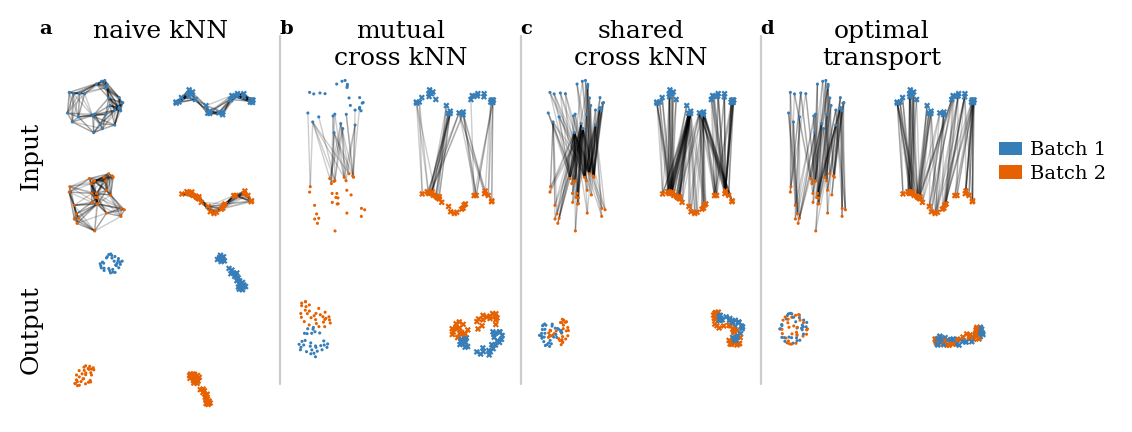

In [21]:
fig = plot_case(batch1_dl, batch2_dl, res_dl, n0=n_dl, sub_seed=seed_dl+2, savepath=OUTPUT_DIR / "fig1_disc_line.png")
fig.savefig(OUTPUT_DIR / "cross_edge_line.png", dpi=300)

---

## 3. Composite figure

The three results above in one figure, laid out as

```
a b c d | m
e f g h | m
i j k l | m
```

- **a-d**: one dataset's embeddings (lupus by default), a pair of panels per method -- batch then
  cell type -- for the unintegrated joint t-SNE and for OT-tSNE. Same drawing as section 1,
  restricted to two of its nine columns.
- **e-l**: the kissing-problem illustration of the cells above, its input row over its output row.
  `draw_case_panels` is the same code that draws it as a figure of its own.
- **m**: the top-3 finishes of section 2, as a single bar column.

Those are the mosaic's keys, not the letters printed. The second panel of an embedding pair and
the illustration's output row are named by the panel above or beside them, so seven panels carry
a letter and they run **a to g** with no gaps: the two embedding pairs, lettered up at their
method heading, then the illustration's input row, then the bars.

`COMPOSITE_FORMS` holds two forms of it. `full` is the layout above; `compact` drops the
illustration's output row and the rules between its columns, and pays for the height it saves by
giving the bar panel more width and dropping the methods that placed only once. Each is drawn in
a cell of its own and writes a PDF named by the form's `stem`.

Both forms go through `draw_case_panels`, defined with `run_case` above, so re-run that cell
before these. A stale copy of it still expects an output row and the compact form then fails with
`IndexError: index 1 is out of bounds`.

The blocks are subfigures, so a form's `bar_fraction` is the share of the figure width that `m`
really gets, method names included. The keys sit in white space the data leaves free rather than
in a band of their own -- except the compact form's batch key, which gets a strip under the
illustration, height the bar panel's x axis already holds open on the right. The illustration is
drawn in the embedding figure's batch colours, so one batch key covers every panel that shows a
batch. The figure is set sans-serif, against the serif paper style.

The embedding scatters of a and b are rasterized at `SAVE_DPI`; everything else, the illustration
included, stays vector.

In [ ]:
# Composite figure settings

# `{stem}` is filled in per form. Set to None to draw without writing anything.
COMPOSITE_OUTPUT_PATH = OUTPUT_DIR / "{stem}.pdf"

COMPOSITE_DATASET = "lupus"

# one pair of panels per method, batch first and cell type second
COMPOSITE_COLUMNS = (
    ("joint", "Unintegrated (joint t-SNE)"),
    ("ot", "OT-tSNE"),
)

# Two forms of the same figure. `full` shows the illustration's input row over its output row;
# `compact` drops the output row and the rules between the columns, which takes an inch of height
# out of the figure. What the bar panel loses in height it gets back in width and in a higher
# `min_top_k`, which drops the methods that placed only once.
COMPOSITE_FORMS = {
    "full": {
        "stem": "fig1_w_kissing_embd",
        "layout": ("abcdm", "efghm", "ijklm"),
        # the illustration carries far more white space than the embeddings, so its rows are shorter
        "row_ratios": (1.0, 0.75, 0.75),
        "row_titles": ("Input graph", "Visualization"),
        "height": 2.75,
        # m's share of the figure width. It has to hold the method names as well as the bars, so
        # it is the one number in this figure worth re-checking after any change to the method set.
        "bar_fraction": 0.45,
        "rules": True,
        "min_top_k": 1,
        "legend_band": 0.0,
        "batch_legend_at": ("l", "upper right"),
        "batch_ncol": 1,
        # anchored rather than given in axes coordinates: the key is nearly as wide as the bars
        # and an absolute x that clears them on one machine clips its longest label on the next
        "bar_legend_loc": (0.34, 0.01), #"lower right",
    },
    "compact": {
        "stem": "fig1_w_kissing_embd_compact",
        "layout": ("abcdm", "efghm"),
        "row_ratios": (1.0, 1.0),
        # with no output row to tell it apart from, the remaining row needs no label
        "row_titles": (),
        "height": 2.05,
        # wider than the full form's: the key is the same nine rows tall but the bar panel is
        # shorter, so the only room left for it is sideways
        "bar_fraction": 0.50,
        "rules": False,
        "min_top_k": 2,
        # no panel has room for it once the output row is gone, so it gets a strip of its own
        # under the illustration -- height the bar panel's x axis already spends on the right and
        # the illustration would otherwise waste, so the figure does not grow by a millimetre
        "legend_band": 0.16,
        "batch_legend_at": ("band", "center left"),
        "batch_ncol": 2,
        "bar_legend_loc": "lower right",
    },
}

# sans-serif, against the serif paper style, and named rather than left to the family default so
# a machine without Arial degrades to a metric-compatible clone instead of to DejaVu
COMPOSITE_FONT_FAMILY = "sans-serif"
COMPOSITE_FONT_NAMES = ("Arial", "Helvetica", "Nimbus Sans", "Liberation Sans", "DejaVu Sans")

COMPOSITE_FONT_PT = 7.0
COMPOSITE_HEADING_PT = 7.0
COMPOSITE_LETTER_PT = 7.0
COMPOSITE_HEADING_GAP = 0.006     # figure fraction between a pair's letter and its heading

COMPOSITE_CASE_MARKER = 9.0         # illustration marker area, larger than in `plot_case`

# the gap between the mosaic's rows, as constrained layout's fraction of the mean panel height.
# The style file's 0.03 left the view labels of a and b sitting almost on the illustration's
# headings. Widening it costs the embedding panels nothing, because they are square and limited by
# their column's width rather than by their row's height: the height comes out of the illustration
# rows instead, which is also what brings their headings closer to the points below them.
COMPOSITE_BLOCK_HSPACE = 0.15

# the illustration's headings sit closer to their panels than the style's `axes.titlepad`, which
# is the other half of what pays for the wider row gap above them
COMPOSITE_CASE_TITLE_PAD = 1.0

# the embedding panels go into the PDF as a raster at `SAVE_DPI`, the illustration's 120 points
# stay vector. Nothing else about the figure is rasterized.
COMPOSITE_RASTERIZE_EMBEDDINGS = True

# only the illustration's input row is lettered: each output panel sits directly under the input
# panel it belongs to and does not need a letter of its own. The embedding pairs are lettered the
# same way, once per pair and up at the method heading.
COMPOSITE_CASE_LETTER_ROWS = (0,)

# letters are handed out in reading order to the panels that get one -- the two embedding pairs,
# then the illustration's input row, then the bars -- and so run a, b, c, ... with no gaps. They
# are deliberately not the mosaic keys of a form's `layout`, which name every panel including the
# ones that stay unlettered. Both forms therefore letter the same panels the same way.
COMPOSITE_LETTERS = "abcdefghijklmnopqrstuvwxyz"

# both keys sit inside panels rather than in a band of their own, so each has to be told where the
# data leaves room -- see each form's `batch_legend_at` (panel and corner) and `bar_legend_loc`.
COMPOSITE_BAR_LEGEND_NCOL = 1

COMPOSITE_RULE_PAD = 0.01           # figure fraction, how far the column rules clear the panels

In [201]:
# Composite figure helpers

def composite_embedding_colours(arrays):
    """Per-cell colours for the two views of one dataset, keyed by the view's own label.

    Same construction as `embedding_panels`: the batch ids index the two batch colours, and the
    per-batch label arrays have to be concatenated before they line up with them.
    """
    palette = cell_type_palette(tuple(str(x) for x in arrays["label_names"]))
    return {
        "Batch": np.asarray(QUALITATIVE_BATCH_COLOURS)[np.asarray(arrays["batch_ids"], dtype=int)],
        "Cell type": palette[
            np.concatenate([arrays["labels0"], arrays["labels1"]]).astype(int)
        ],
    }


def draw_embedding_panel(ax, emb, colors, order, *, rasterized=COMPOSITE_RASTERIZE_EMBEDDINGS):
    """One embedding scatter into an existing axes, framed on the bulk of its points.

    The scatter is rasterized: these panels carry ten thousand points each, and as vector output
    they would dominate the file and make the page slow to render. Everything around them -- text,
    rules, the bars -- stays vector, and `SAVE_DPI` is what the raster is resolved at.
    """
    ax.scatter(emb[order, 0], emb[order, 1], c=colors[order], s=point_size(len(emb)),
               alpha=0.7, linewidths=0, edgecolors="none", zorder=-1, rasterized=rasterized)
    ax.set(xticks=[], yticks=[])
    fill_panel(ax, emb)
    for spine in ax.spines.values():
        spine.set_visible(False)


def draw_top_three(ax, counts, *, min_top_k=1, segment_order=BAR_SEGMENT_ORDER):
    """The top-3 bars in one existing axes, returning `(handles, labels)` instead of a legend.

    This is `top_three_finishes` with the figure and the gridspec taken out: the composite owns
    the layout. The key comes back rather than being drawn so that it can be placed once the
    bars have set the x limit it has to stay clear of.

    `min_top_k` is the shortest bar worth a row. 1 keeps every method that placed at all, which
    is what the standalone figure shows; raising it buys height back for a shorter figure, at the
    cost of not showing how far the tail runs.
    """
    order = bar_method_order(counts)
    totals = counts.groupby("method_key")["n_top_k"].sum().reindex(order)
    if min_top_k:
        order = [key for key in order if totals[key] >= min_top_k]
        totals = totals.reindex(order)
        counts = counts[counts["method_key"].isin(order)]

    hues = dict(CLUSTER_DATASET_PALETTE)
    per_dataset = [d for d in hues if d in set(counts["dataset"])]
    span = max(1.0, float(totals.max()))
    wides = {
        column: counts.pivot_table(
            index="method_key", columns="dataset", values=column, aggfunc="sum", fill_value=0,
        ).reindex(columns=per_dataset, fill_value=0)
        for column, _hatch in BAR_PARTS
    }

    draw_bar_column(ax, order, wides, totals, hues=hues, per_dataset=per_dataset, span=span,
                    segment_order=segment_order)
    trim_axis([ax])
    ax.set_xlabel("Top-3 finishes")

    handles = [
        Line2D([], [], marker="s", linestyle="none", markersize=4,
               markerfacecolor=hues[d], markeredgecolor="none")
        for d in per_dataset
    ] + [
        Patch(facecolor="#9a9a9a", edgecolor="#ffffff", linewidth=0.4, hatch="////"),
        Patch(facecolor="#9a9a9a", edgecolor="#ffffff", linewidth=0.4),
    ]
    labels = [FINAL_DATASET_LABELS.get(d, d) for d in per_dataset] + [
        "Bio conservation", "Batch mixing",
    ]
    return handles, labels


def composite_legends(batch_ax, bars_ax, bar_key, *, colours=QUALITATIVE_BATCH_COLOURS,
                      batch_loc="upper right", batch_ncol=1, bar_loc="lower right",
                      bar_ncol=COMPOSITE_BAR_LEGEND_NCOL):
    """Both keys inside panels, in white space the data leaves free.

    The batch key goes into one of the illustration's panels and the bar breakdown into the corner
    of the bar panel that the short bars leave empty, so the figure needs no legend band and stays
    as short as its panels. One batch key serves a-l, which is why the illustration was moved onto
    the embedding figure's batch colours.
    """
    batch_handles = [
        Line2D([], [], marker="o", linestyle="none", markersize=4,
               markerfacecolor=colour, markeredgecolor="none")
        for colour in colours
    ]
    batch = batch_ax.legend(
        batch_handles, list(QUALITATIVE_BATCH_LABELS), loc=batch_loc, ncol=batch_ncol,
        frameon=False, borderaxespad=0.0, handletextpad=QUALITATIVE_HANDLETEXTPAD,
        columnspacing=QUALITATIVE_COLUMNSPACING, labelspacing=0.3,
    )
    bars = bars_ax.legend(*bar_key, loc=bar_loc, ncol=bar_ncol, frameon=False,
                          borderaxespad=BAR_LEGEND_PAD, handletextpad=0.4, columnspacing=1.0,
                          labelspacing=0.35)

    # neither key takes part in the layout. Both are aimed by hand at space the data already
    # leaves free, and a key placed outside its panel would otherwise be charged to that panel's
    # column and squeeze every panel in it.
    for legend in (batch, bars):
        legend.set_in_layout(False)

In [202]:
# Draw the composite figure

def composite_figure(batch1, batch2, res, n0, counts, *, layout, row_ratios, row_titles, height,
                     bar_fraction, rules, min_top_k, legend_band, batch_legend_at, batch_ncol,
                     bar_legend_loc,
                     dataset=COMPOSITE_DATASET, columns=COMPOSITE_COLUMNS, width=FULL_WIDTH,
                     marker=COMPOSITE_CASE_MARKER, sub_seed=0, plot_seed=0):
    """The three results of this notebook in one figure, `m` running the full height:

        a b c d | m
        e f g h | m
        i j k l | m

    a-d are one dataset's embeddings, a pair of panels per method; e-l are the kissing-problem
    illustration; m is the top-3 bars. Those are the mosaic's own keys, not the letters printed:
    the second panel of an embedding pair and the illustration's output row are named by the panel
    above or beside them, and the seven panels that do get a letter are lettered a to g in reading
    order. A `layout` of two rows drops the output row, and the letters do not move.

    The two blocks are subfigures rather than cells of one gridspec. A gridspec would hand the
    method names down the side of m to every column as a shared margin and leave the panels a
    third of their width; subfigures also make `bar_fraction` mean what it says, since each block
    then gets that share of the figure outright and pays for its own labels out of it.
    """
    rows = [list(row)[:-1] for row in layout]
    panels = [(key, view) for key, _heading in columns for view in ("Batch", "Cell type")]

    # one letter per lettered panel, in reading order, so the printed sequence has no gaps
    alphabet = iter(COMPOSITE_LETTERS)
    pair_letters = [next(alphabet) for _ in columns]
    case_letters = "".join(next(alphabet) for _ in rows[1])
    bar_letter = next(alphabet)

    arrays = EMBEDDINGS[dataset]
    colours = composite_embedding_colours(arrays)

    sizes = {key: COMPOSITE_FONT_PT for key in
             ("font.size", "axes.titlesize", "axes.labelsize", "xtick.labelsize",
              "ytick.labelsize", "legend.fontsize")}
    sizes["figure.constrained_layout.hspace"] = COMPOSITE_BLOCK_HSPACE
    sizes["font.family"] = COMPOSITE_FONT_FAMILY
    sizes[f"font.{COMPOSITE_FONT_FAMILY}"] = list(COMPOSITE_FONT_NAMES)
    with plt.rc_context(sizes):
        fig = plt.figure(figsize=(width, height))
        block, bars = fig.subfigures(1, 2, width_ratios=[1 - bar_fraction, bar_fraction])

        # a form with no room for the batch key inside a panel gets a strip under the illustration.
        # It is free height: the bar panel's tick labels and axis label already hold the same band
        # open on the right, and the illustration block would simply run past it.
        band_ax = None
        if legend_band:
            block, band = block.subfigures(2, 1, height_ratios=[1 - legend_band, legend_band])
            band_ax = band.subplots()
            band_ax.axis("off")

        axd = block.subplot_mosaic(rows, height_ratios=list(row_ratios))
        bars_ax = bars.subplots()

        # a-d: the embedding pairs. The view label goes under its panel, not over it: over it it
        # followed the method heading directly and the two read as one phrase, so "Unintegrated
        # (joint t-SNE)" above "Batch" was being read as "unintegrated batch". The title is left as
        # one blank line, which is the row the method headings are placed into once the layout is
        # settled.
        view_labels = {}
        rng = np.random.default_rng(SEED)
        orders = {key: rng.permutation(len(arrays[f"embedding__{key}"]))
                  for key, _heading in columns}
        for letter, (key, view) in zip(rows[0], panels):
            ax = axd[letter]
            draw_embedding_panel(ax, np.asarray(arrays[f"embedding__{key}"]), colours[view],
                                 orders[key])
            ax.set_xlabel(view)
            view_labels[letter] = ax.set_title(" ")

        # e-l: the kissing-problem illustration, carrying on the letter sequence
        case_ax = np.array([[axd[letter] for letter in row] for row in rows[1:]])
        case_drawn = draw_case_panels(case_ax, batch1, batch2, res, n0, s=marker,
                                      letters=case_letters, row_titles=row_titles,
                                      letter_rows=COMPOSITE_CASE_LETTER_ROWS,
                                      letter_pt=COMPOSITE_LETTER_PT, sub_seed=sub_seed,
                                      title_pad=COMPOSITE_CASE_TITLE_PAD,
                                      plot_seed=plot_seed, legend_ax=None)

        # m: the bars. Both keys go into the white space of the panels they belong to.
        bar_key = draw_top_three(bars_ax, counts, min_top_k=min_top_k)
        batch_panel, batch_loc = batch_legend_at
        composite_legends(band_ax if batch_panel == "band" else axd[batch_panel],
                          bars_ax, bar_key, batch_loc=batch_loc,
                          batch_ncol=batch_ncol, bar_loc=bar_legend_loc)

        fig.canvas.draw()
        inv = fig.transFigure.inverted()
        extent = lambda artist: artist.get_window_extent().transformed(inv)

        # every panel letter goes flush with the left boundary of the column it labels, so the
        # letters line up down the figure whatever else sits in the margin beside them
        edges = column_letter_edges(fig, np.array([[axd[key] for key in row] for row in rows]))

        # the method headings, centred over each pair of embedding panels, with the pair's letter
        # on the same line. Placed after the layout rather than as titles: a heading this wide
        # over a panel this narrow would otherwise be centred on one panel instead of on the pair.
        for index, ((_key, heading), letter) in enumerate(zip(columns, pair_letters)):
            pair = (rows[0][2 * index], rows[0][2 * index + 1])
            right = extent(axd[pair[1]])
            top = extent(view_labels[pair[0]]).y1
            mark = fig.text(edges[2 * index], top, letter, ha="left",
                            va="top", fontweight="bold", fontsize=COMPOSITE_LETTER_PT)
            # the heading is centred on what the letter leaves it, not on the pair. Centred on
            # the pair it runs into the letter as soon as the block narrows, and the first pair
            # has no margin to the left to be pushed into.
            start = extent(mark).x1 + COMPOSITE_HEADING_GAP
            fig.text(0.5 * (start + right.x1), top, heading, ha="center", va="top",
                     fontsize=COMPOSITE_HEADING_PT)

        # the illustration's letters, up on the top line of their wrapped headings and out at the
        # left boundary of the column each one labels
        align_letters_to_titles(case_drawn)
        align_letters_to_edges(fig, case_drawn, edges)

        # the bars' letter goes on the embeddings' heading line, at the left edge of its block and
        # so clear of the method names. Its own panel reaches the top of the figure, with no room
        # above it.
        fig.text(bars_ax.get_tightbbox().transformed(inv).x0, top, bar_letter,
                 ha="left", va="top", fontweight="bold", fontsize=COMPOSITE_LETTER_PT)

        # the column rules belong to the illustration only, so they stop at its top and bottom
        if rules:
            case_column_rules(fig, case_ax,
                              ylim=(extent(case_ax[-1, 0]).y0 - COMPOSITE_RULE_PAD,
                                    extent(case_ax[0, 0]).y1 + COMPOSITE_RULE_PAD))
    return fig


def draw_composite(form):
    """Draw one named form and, if `COMPOSITE_OUTPUT_PATH` is set, write it under its own stem.

    Each form gets a cell of its own below, so that re-running one does not redraw the other and
    an error in one does not hide the other's figure.
    """
    settings = dict(COMPOSITE_FORMS[form])
    stem = settings.pop("stem")
    fig = composite_figure(batch1_dl, batch2_dl, res_dl, n_dl, COUNTS,
                           sub_seed=seed_dl + 2, **settings)
    if COMPOSITE_OUTPUT_PATH is not None:
        path = Path(str(COMPOSITE_OUTPUT_PATH).format(stem=stem))
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=SAVE_DPI, bbox_inches=None)
        print(f"wrote {path}")
    return fig

wrote /gpfs01/berens/user/sdamrich/mirrored_code/ne_aligned/data_and_figures/data_and_figures/data_final_ICLR/fig1_w_kissing_embd.pdf


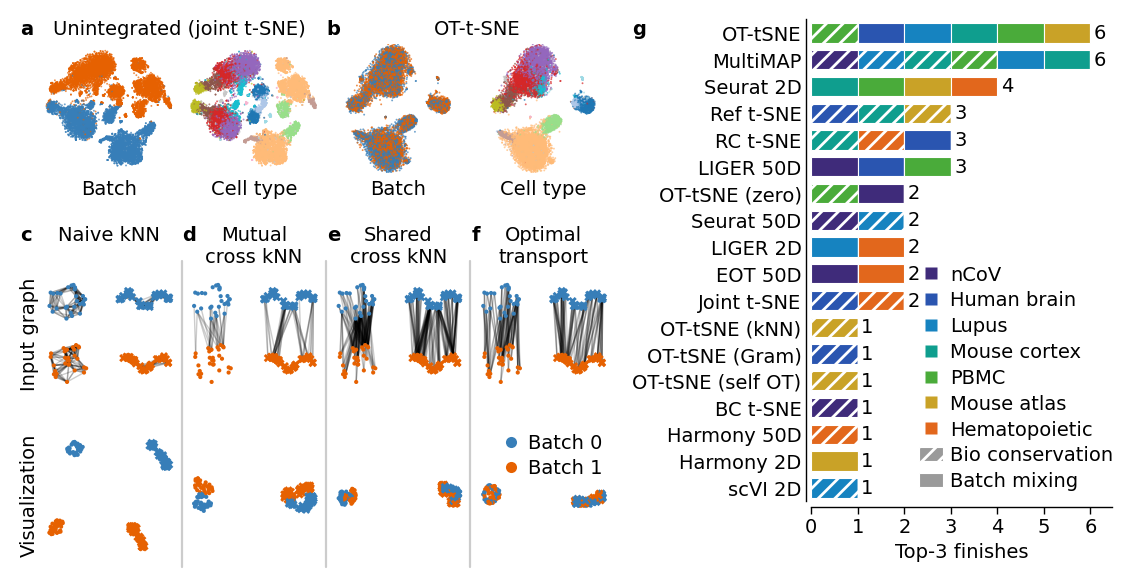

In [203]:
# The full figure: the illustration's input row over its output row

fig_full = draw_composite("full")
plt.show()